# Part 2 - Linear Regression

In this part, we compare different ways to fit linear regression and see what happens when the data become harder to work with. We first test the methods on generated data, then compare theory with simulations, and finally use real datasets.

The calculations use NumPy and SciPy. We only use scikit-learn to load datasets and in the library comparison section. The same helper functions are kept in `mlcore.py`.

We can set FAST = True while working on the notebook. To get the final results, we need to set it to False and run all cells again. The full timing experiment in 2.6 may take a long time.

## Setup

In [1]:
from pathlib import Path
import csv
import json
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from mlcore import (
    add_bias, gradient_check, standardize, linear_loss, linear_grad,
    solve_naive_inverse, solve_svd, solve_lstsq, solve_gd, solve_lbfgs,
    linear_lstsq, mse, r2_score_numpy, stratified_split, pocket_pla
)

SEED = 407
FAST = False
FIG_DIR = Path('figures')
RESULTS_DIR = Path('results')
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print('FAST:', FAST, '| Seed:', SEED)

FAST: False | Seed: 407


## 2.2 Five solvers

We minimize the same mean squared error with five methods. The inverse, SVD, and least squares methods find the weights directly. Gradient descent and L-BFGS-B improve the weights through optimization. On a well-conditioned dataset, their results should be almost identical.

### Test data

In [2]:
rng = np.random.default_rng(SEED)
N, d = 300, 2
X = add_bias(rng.normal(size=(N, d)))
w_true = np.array([1.5, -2.0, 0.8])
y = X @ w_true + 0.1 * rng.normal(size=N)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Condition number of X:", f"{np.linalg.cond(X):.2f}")
print("True weights:", w_true)

X shape: (300, 3)
y shape: (300,)
Condition number of X: 1.15
True weights: [ 1.5 -2.   0.8]


### Gradient

Our derivative of the squared error is $\nabla E_{\mathrm{in}}(w)=\frac{2}{N}X^T(Xw-y)$. We compare it with a numerical derivative before using it for optimization.

In [3]:
w_probe = rng.normal(size=X.shape[1])
relative_error = gradient_check(
    lambda w: linear_loss(w, X, y),
    lambda w: linear_grad(w, X, y),
    w_probe
)
print(f'Gradient relative error: {relative_error:.3e}')
assert relative_error < 1e-6

Gradient relative error: 1.148e-11


### Solver results

In [4]:
w_inv = solve_naive_inverse(X, y)
w_svd = solve_svd(X, y)
w_qr = solve_lstsq(X, y)
w_gd, gd_history, gd_steps, gd_converged, gd_eta = solve_gd(X, y)
lbfgs_result = solve_lbfgs(X, y)
w_lbfgs = lbfgs_result.x

solutions = {
    "Naive inverse": w_inv,
    "SVD pseudoinverse": w_svd,
    "LSTSQ": w_qr,
    "Batch GD": w_gd,
    "L-BFGS-B": w_lbfgs,
}

print(f"GD: {gd_steps} iterations, converged={gd_converged}, eta={gd_eta:.4g}")
print(f"L-BFGS-B: {lbfgs_result.nit} iterations, success={lbfgs_result.success}")
print()
print(f"{'Method':<18} {'Train MSE':>12} {'Max |w - w_lstsq|':>20}")
for name, w in solutions.items():
    print(f"{name:<18} {linear_loss(w, X, y):>12.8f} {np.max(np.abs(w-w_qr)):>20.3e}")

print("\nFitted weights (LSTSQ):", np.round(w_qr, 6))
assert gd_converged, "GD reached the iteration limit"
assert linear_loss(w_lbfgs, X, y) - linear_loss(w_qr, X, y) < 1e-8
for name, w in solutions.items():
    assert np.max(np.abs(w - w_qr)) < 1e-4, f"{name} differs too much"
    assert linear_loss(w, X, y) - linear_loss(w_qr, X, y) < 1e-8
print("\nPASS: All five solvers agree on this well-conditioned dataset.")

GD: 26 iterations, converged=True, eta=0.3638
L-BFGS-B: 6 iterations, success=True

Method                Train MSE    Max |w - w_lstsq|
Naive inverse        0.00972694            3.553e-15
SVD pseudoinverse    0.00972694            8.882e-16
LSTSQ                0.00972694            0.000e+00
Batch GD             0.00972694            3.823e-11
L-BFGS-B             0.00972694            1.980e-11

Fitted weights (LSTSQ): [ 1.495452 -2.004245  0.807502]

PASS: All five solvers agree on this well-conditioned dataset.


### GD convergence

The loss should decrease and get close to the least squares minimum. This plot is useful to check that gradient descent works as expected.

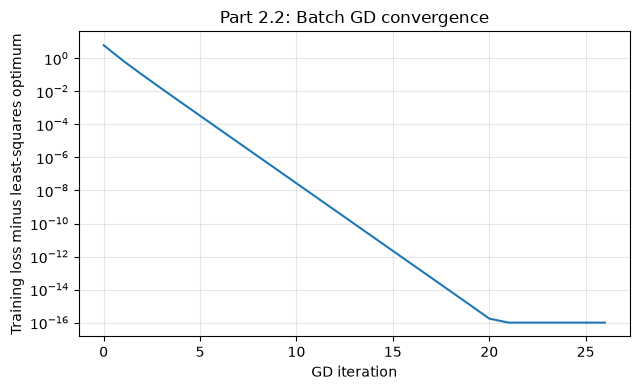

In [5]:
loss_gap = np.maximum(gd_history - linear_loss(w_qr, X, y), 1e-16)

plt.figure(figsize=(6.5, 4))
plt.semilogy(np.arange(len(loss_gap)), loss_gap)
plt.xlabel("GD iteration")
plt.ylabel("Training loss minus least-squares optimum")
plt.title("Part 2.2: Batch GD convergence")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/part2_2_gd_convergence.png", dpi=180)
plt.show()

The five methods should have almost the same MSE on this dataset. The inverse is included because the next experiment will show when it becomes unreliable.

## 2.3 Conditioning

Here we make two features almost equal: $x_2=x_1+\delta u$. Smaller values of $\delta$ make the problem harder. For each solver, we measure how close its weights are to the true weights and how closely its predictions fit the data. We also count how many GD iterations are needed.

The full experiment uses 100 runs per value of $\delta$. Failed solvers are recorded instead of being removed from the analysis.

### Data and settings

In [6]:
RUNS23 = 10 if FAST else 100
N23 = 200
N = N23
NOISE_STD = 1e-4
W_STAR = np.array([1.0, 2.0, -1.0])
DELTAS = 10.0 ** (-np.arange(1, 9))
GD_REL_TOL = 1e-4
GD_MAX_ITER = 8000 if FAST else 30000
rng23 = np.random.default_rng(SEED)
print(f'Runs per delta: {RUNS23}, iteration limit: {GD_MAX_ITER}')

Runs per delta: 100, iteration limit: 30000


### Gradient descent for repeated runs

In [7]:
def solve_gd_batched(X_many, y_many, w_refs, max_iter, rel_tol):
    """Equivalent quadratic gradient 2/N X^T(Xw-y), vectorized over runs.

    Stops each run at a fixed RELATIVE COEFFICIENT tolerance to a stable
    least-squares reference; marks unfinished runs as censored. Uses the
    stable spectral step eta=0.8/L, L=2||X||_2^2/N.
    """
    R, n, p = X_many.shape
    gram = (2.0 / n) * np.einsum('rni,rnj->rij', X_many, X_many)
    rhs = (2.0 / n) * np.einsum('rni,rn->ri', X_many, y_many)
    largest_s = np.linalg.svd(X_many, compute_uv=False)[:, 0]
    eta = 0.8 / ((2.0 / n) * largest_s ** 2)

    w = np.zeros((R, p))
    converged = np.zeros(R, dtype=bool)
    iterations_used = np.full(R, max_iter, dtype=int)
    ref_scale = np.maximum(1.0, np.linalg.norm(w_refs, axis=1))

    for t in range(1, max_iter + 1):
        active = ~converged
        if not np.any(active):
            break
        gradient = np.einsum('rij,rj->ri', gram, w) - rhs
        w[active] -= eta[active, None] * gradient[active]
        gap = np.linalg.norm(w - w_refs, axis=1) / ref_scale
        just_converged = active & (gap <= rel_tol)
        iterations_used[just_converged] = t
        converged[just_converged] = True

    return w, iterations_used, converged, eta

### Run experiment

In [8]:
METHODS = ["Naive inverse", "SVD", "LSTSQ", "Batch GD", "L-BFGS-B"]
M = len(METHODS)
D = len(DELTAS)
coefficient_errors = np.full((M, D, RUNS23), np.nan)
training_residuals = np.full((M, D, RUNS23), np.nan)
condition_numbers = np.full((D, RUNS23), np.nan)
solver_succeeded = np.zeros((M, D, RUNS23), dtype=bool)
gd_iterations = np.full((D, RUNS23), GD_MAX_ITER, dtype=int)
gd_converged = np.zeros((D, RUNS23), dtype=bool)
lbfgs_iterations = np.full((D, RUNS23), -1, dtype=int)

# Independent samples ACROSS RUNS23; paired across DELTAS.
x1 = rng23.normal(size=(RUNS23, N))
u = rng23.normal(size=(RUNS23, N))
noise = NOISE_STD * rng23.normal(size=(RUNS23, N))


def construct_data(delta):
    X_many = np.ones((RUNS23, N, 3))
    X_many[:, :, 1] = x1
    X_many[:, :, 2] = x1 + delta * u
    y_many = np.einsum('rni,i->rn', X_many, W_STAR) + noise
    return X_many, y_many


for j, delta in enumerate(DELTAS):
    X_many, y_many = construct_data(delta)
    svals = np.linalg.svd(X_many, compute_uv=False)
    condition_numbers[j] = svals[:, 0] / svals[:, -1]
    w_ref = np.array([solve_lstsq(X_many[r], y_many[r]) for r in range(RUNS23)])

    # Gradient descent is batched for speed, but uses the same GD update.
    w_gd, steps, gd_ok, _ = solve_gd_batched(
        X_many, y_many, w_ref, GD_MAX_ITER, GD_REL_TOL
    )
    gd_iterations[j] = steps
    gd_converged[j] = gd_ok

    for r in range(RUNS23):
        Xr, yr = X_many[r], y_many[r]
        estimates = [None] * M
        try:
            estimates[0] = solve_naive_inverse(Xr, yr)
            solver_succeeded[0, j, r] = True
        except np.linalg.LinAlgError:
            pass
        estimates[1] = solve_svd(Xr, yr)
        solver_succeeded[1, j, r] = True
        estimates[2] = w_ref[r]
        solver_succeeded[2, j, r] = True
        estimates[3] = w_gd[r]
        solver_succeeded[3, j, r] = gd_ok[r]
        result = solve_lbfgs(Xr, yr)
        estimates[4] = result.x
        solver_succeeded[4, j, r] = result.success
        lbfgs_iterations[j, r] = result.nit

        for m, w_hat in enumerate(estimates):
            if w_hat is None or not np.all(np.isfinite(w_hat)):
                solver_succeeded[m, j, r] = False
                continue
            coefficient_errors[m, j, r] = np.linalg.norm(w_hat - W_STAR)
            training_residuals[m, j, r] = np.linalg.norm(Xr @ w_hat - yr)

    print(f"delta={delta:.0e}  median kappa(X)={np.median(condition_numbers[j]):.3e}  "
          f"GD converged={gd_converged[j].sum()}/{RUNS23}  "
          f"naive inverse finite={np.isfinite(coefficient_errors[0,j]).sum()}/{RUNS23}")

assert np.all(np.diff(np.median(condition_numbers, axis=1)) > 0)
assert np.all(np.isfinite(coefficient_errors[2]))
print("PASS: all required deltas completed")

delta=1e-01  median kappa(X)=2.035e+01  GD converged=100/100  naive inverse finite=100/100
delta=1e-02  median kappa(X)=2.023e+02  GD converged=0/100  naive inverse finite=100/100
delta=1e-03  median kappa(X)=2.022e+03  GD converged=0/100  naive inverse finite=100/100
delta=1e-04  median kappa(X)=2.022e+04  GD converged=0/100  naive inverse finite=100/100
delta=1e-05  median kappa(X)=2.022e+05  GD converged=0/100  naive inverse finite=100/100
delta=1e-06  median kappa(X)=2.022e+06  GD converged=0/100  naive inverse finite=100/100
delta=1e-07  median kappa(X)=2.022e+07  GD converged=0/100  naive inverse finite=100/100
delta=1e-08  median kappa(X)=2.022e+08  GD converged=0/100  naive inverse finite=88/100
PASS: all required deltas completed


### Numerical results

In [9]:
def mean_se(values):
    """Arithmetic mean and standard error, ignoring nonfinite solver failures."""
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return np.nan, np.nan, 0
    return (float(np.mean(a)),
            float(np.std(a, ddof=1) / np.sqrt(len(a))) if len(a) > 1 else np.nan,
            len(a))

rows = []
for j, delta in enumerate(DELTAS):
    kap_mean, kap_se, _ = mean_se(condition_numbers[j])
    for m, method in enumerate(METHODS):
        ce, ce_se, num = mean_se(coefficient_errors[m, j])
        residual, residual_se, _ = mean_se(training_residuals[m, j])
        rows.append(dict(delta=delta, method=method, repetitions=RUNS23,
                         mean_kappa=kap_mean, se_kappa=kap_se,
                         mean_coefficient_error=ce, se_coefficient_error=ce_se,
                         mean_residual=residual, se_residual=residual_se,
                         valid_runs=num, successful_runs=int(solver_succeeded[m, j].sum())))

with open('results/part2_3_summary.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

np.savez_compressed('results/part2_3_raw.npz',
                    deltas=DELTAS, conditions=condition_numbers,
                    coefficient_errors=coefficient_errors,
                    training_residuals=training_residuals,
                    gd_iterations=gd_iterations, gd_converged=gd_converged,
                    lbfgs_iterations=lbfgs_iterations,
                    solver_succeeded=solver_succeeded, methods=np.array(METHODS),
                    w_star=W_STAR, noise_std=NOISE_STD)

print(f"{'delta':<9} {'solver':<15} {'coefficient error (mean ± SE)':<32} {'residual (mean ± SE)':<28}")
for j in [0, 3, 7]:
    for m, name in enumerate(METHODS):
        ce, cs, _ = mean_se(coefficient_errors[m, j])
        re, rs, _ = mean_se(training_residuals[m, j])
        print(f"{DELTAS[j]:<9.0e} {name:<15} {ce:9.3e} ± {cs:<9.2e} "
              f"{re:9.3e} ± {rs:<9.2e}")
print("Saved: results/part2_3_summary.csv and part2_3_raw.npz")

delta     solver          coefficient error (mean ± SE)    residual (mean ± SE)        
1e-01     Naive inverse   9.088e-05 ± 7.29e-06  1.410e-03 ± 6.50e-06 
1e-01     SVD             9.088e-05 ± 7.29e-06  1.410e-03 ± 6.50e-06 
1e-01     LSTSQ           9.088e-05 ± 7.29e-06  1.410e-03 ± 6.50e-06 
1e-01     Batch GD        2.554e-04 ± 1.16e-05  1.431e-03 ± 6.40e-06 
1e-01     L-BFGS-B        9.088e-05 ± 7.29e-06  1.410e-03 ± 6.50e-06 
1e-04     Naive inverse   8.931e-02 ± 7.36e-03  1.410e-03 ± 6.50e-06 
1e-04     SVD             8.931e-02 ± 7.36e-03  1.410e-03 ± 6.50e-06 
1e-04     LSTSQ           8.931e-02 ± 7.36e-03  1.410e-03 ± 6.50e-06 
1e-04     Batch GD        2.121e+00 ± 1.77e-06  2.529e-03 ± 1.22e-05 
1e-04     L-BFGS-B        1.191e+00 ± 1.01e-01  2.008e-03 ± 5.55e-05 
1e-08     Naive inverse   2.787e+02 ± 3.52e+01  3.986e+00 ± 3.90e-01 
1e-08     SVD             8.931e+02 ± 7.36e+01  1.410e-03 ± 6.50e-06 
1e-08     LSTSQ           8.931e+02 ± 7.36e+01  1.410e-03 ± 6.50e-06 
1e

### Error plots

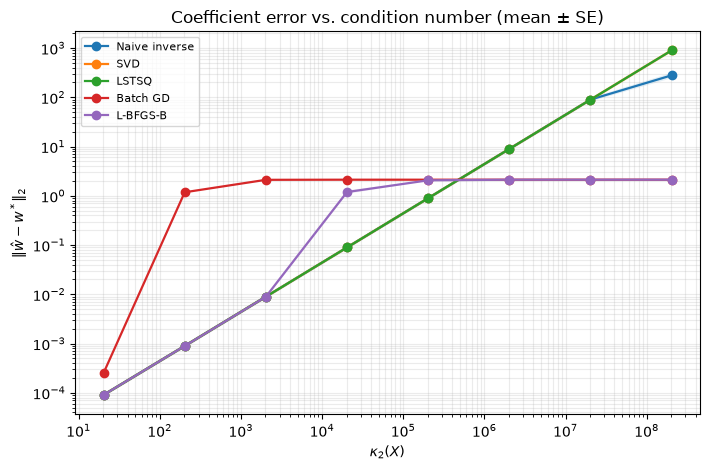

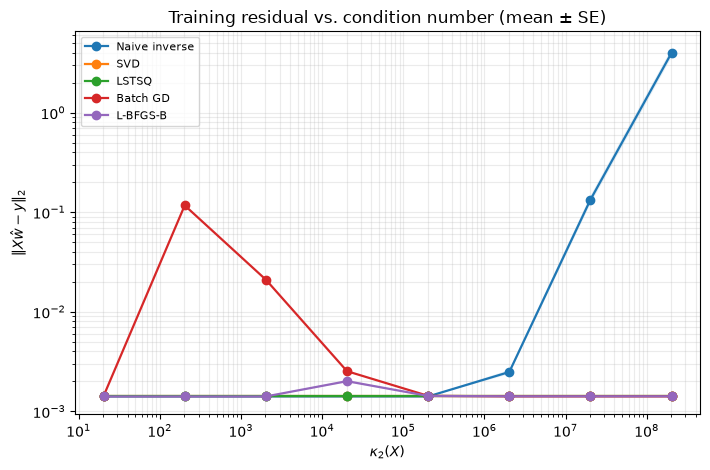

In [10]:
mean_kappa = np.mean(condition_numbers, axis=1)


def plot_metric(metric, ylabel, name, title):
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    for m, method in enumerate(METHODS):
        mu = np.array([mean_se(metric[m, j])[0] for j in range(D)])
        se = np.array([mean_se(metric[m, j])[1] for j in range(D)])
        valid = np.isfinite(mu) & (mu > 0)
        ax.loglog(mean_kappa[valid], mu[valid], 'o-', linewidth=1.6, label=method)
        if valid.sum():
            lower = np.maximum(mu[valid] - se[valid], 1e-16)
            upper = mu[valid] + se[valid]
            ax.fill_between(mean_kappa[valid], lower, upper, alpha=0.12)
    ax.set_xlabel(r'$\kappa_2(X)$')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig('figures/' + name + '.pdf', bbox_inches='tight')
    fig.savefig('figures/' + name + '.png', dpi=200, bbox_inches='tight')
    plt.show()

plot_metric(coefficient_errors, r'$\|\hat{w}-w^*\|_2$',
            'part2_3_coefficient_error',
            'Coefficient error vs. condition number (mean ± SE)')
plot_metric(training_residuals, r'$\|X\hat{w}-y\|_2$',
            'part2_3_training_residual',
            'Training residual vs. condition number (mean ± SE)')

### GD iterations

We use a fixed tolerance for the difference from the least squares coefficients. If GD does not reach it in the allowed number of iterations, its run is marked as capped. That value is not the real time to convergence.

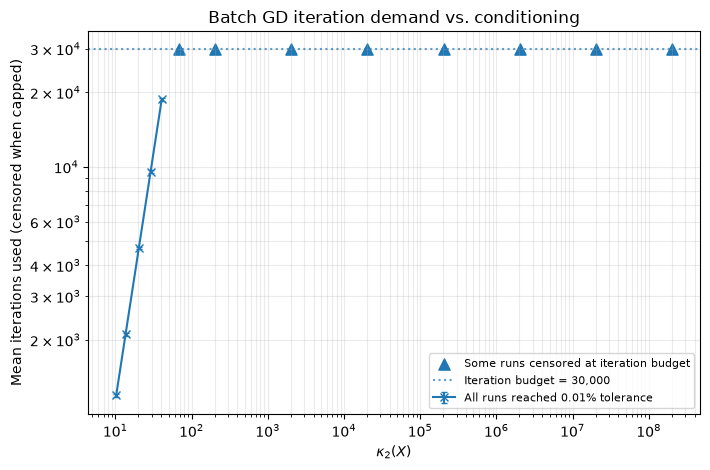

delta       mean kappa        iterations used mean ± SE    converged
2e-01             10.3        1192.5 ± 14.9         100/100
1e-01             13.6        2102.3 ± 26.0         100/100
1e-01             20.3        4700.9 ± 57.4         100/100
7e-02               29        9567.8 ± 116.0        100/100
5e-02             40.6       18727.3 ± 226.2        100/100
3e-02             67.6       30000.0 ± 0.0          0/100
1e-02              203       30000.0 ± 0.0          0/100
1e-03         2.03e+03       30000.0 ± 0.0          0/100
1e-04         2.03e+04       30000.0 ± 0.0          0/100
1e-05         2.03e+05       30000.0 ± 0.0          0/100
1e-06         2.03e+06       30000.0 ± 0.0          0/100
1e-07         2.03e+07       30000.0 ± 0.0          0/100
1e-08         2.03e+08       30000.0 ± 0.0          0/100
Saved all three graphs as both PDF (Overleaf) and PNG (preview).


In [11]:
GD_DELTAS = np.array(sorted(set(DELTAS.tolist() + [0.2, 0.15, 0.07, 0.05, 0.03]), reverse=True))
gd_kappa_more = np.empty((len(GD_DELTAS), RUNS23))
gd_steps_more = np.full((len(GD_DELTAS), RUNS23), GD_MAX_ITER, dtype=int)
gd_ok_more = np.zeros((len(GD_DELTAS), RUNS23), dtype=bool)

for j, delta in enumerate(GD_DELTAS):
    X_many, y_many = construct_data(delta)
    svals = np.linalg.svd(X_many, compute_uv=False)
    gd_kappa_more[j] = svals[:, 0] / svals[:, -1]
    w_refs = np.array([solve_lstsq(X_many[r], y_many[r]) for r in range(RUNS23)])
    _, steps, ok, _ = solve_gd_batched(X_many, y_many, w_refs, GD_MAX_ITER, GD_REL_TOL)
    gd_steps_more[j] = steps
    gd_ok_more[j] = ok

x = gd_kappa_more.mean(axis=1)
steps_mean = gd_steps_more.mean(axis=1)
steps_se = gd_steps_more.std(axis=1, ddof=1) / np.sqrt(RUNS23)
all_converged = np.all(gd_ok_more, axis=1)

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.errorbar(x[all_converged], steps_mean[all_converged],
            yerr=steps_se[all_converged], fmt='x-', capsize=2,
            label='All runs reached 0.01% tolerance')
if np.any(~all_converged):
    ax.scatter(x[~all_converged], steps_mean[~all_converged],
               marker='^', s=65, label='Some runs censored at iteration budget')
ax.axhline(GD_MAX_ITER, linestyle=':', alpha=0.7,
           label=f'Iteration budget = {GD_MAX_ITER:,}')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\kappa_2(X)$')
ax.set_ylabel('Mean iterations used (censored when capped)')
ax.set_title('Batch GD iteration demand vs. conditioning')
ax.grid(True, which='both', alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('figures/part2_3_gd_iterations.pdf', bbox_inches='tight')
fig.savefig('figures/part2_3_gd_iterations.png', dpi=200, bbox_inches='tight')
plt.show()

with open('results/part2_3_gd_iterations.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['delta', 'mean_kappa', 'mean_iterations_used',
                     'se_iterations_used', 'converged_runs', 'total_runs', 'iteration_budget'])
    for j, delta in enumerate(GD_DELTAS):
        writer.writerow([delta, x[j], steps_mean[j], steps_se[j],
                         int(gd_ok_more[j].sum()), RUNS23, GD_MAX_ITER])

print(f"{'delta':<9} {'mean kappa':>12} {'iterations used mean ± SE':>32} {'converged':>12}")
for j, delta in enumerate(GD_DELTAS):
    print(f"{delta:<9.0e} {x[j]:>12.3g} {steps_mean[j]:>13.1f} ± {steps_se[j]:<12.1f} "
          f"{gd_ok_more[j].sum()}/{RUNS23}")
print('Saved all three graphs as both PDF (Overleaf) and PNG (preview).')

As $\delta$ decreases, the condition number increases. The normal equations square the condition number, so the inverse can become unstable. SVD and least squares can still fit the data, but with strong feature correlation the individual coefficients may be inaccurate. GD becomes slow in directions where the loss changes very little. L-BFGS-B may also stop before recovering the least squares coefficients in these flat directions.

## 2.4 Learning curves

Now we compare the theoretical training and test errors with simulated results. The inputs are Gaussian, there are 10 features, and the output has Gaussian noise with standard deviation 0.5. We train a new model for each run and evaluate it on new test points.

The full experiment uses 500 runs for every training size. It includes small sizes near the number of model parameters, where the approximate test error may not be accurate.

### Settings

In [12]:
RUNS = 500 if not FAST else 20
N_TEST = 10_000 if not FAST else 1_000  # fresh test samples FOR EACH run
D = 10
P = D + 1            # intercept + d Gaussian features
SIGMA = 0.5

# Dense coverage near the interpolation threshold N = d+1, plus large N.
N_VALUES = np.array([12, 13, 14, 15, 16, 18, 20, 22, 25, 30,
                     40, 50, 75, 100, 125, 150, 175, 200])

FIGURES_DIR = Path('figures')
RESULTS_DIR = Path('results')
FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# A fixed target; no target variability is mixed into the learning curves.
w_true = np.r_[0.5, np.linspace(-1.0, 1.0, D)]

assert P == 11 and N_VALUES[0] > P
assert SIGMA == 0.5 and D == 10
print(f'FAST={FAST}; seed={SEED}; N values={len(N_VALUES)}')
print(f'Runs per N={RUNS}; fresh test points per run={N_TEST:,}')
print('True parameter vector:', w_true)

FAST=False; seed=407; N values=18
Runs per N=500; fresh test points per run=10,000
True parameter vector: [ 0.5        -1.         -0.77777778 -0.55555556 -0.33333333 -0.11111111
  0.11111111  0.33333333  0.55555556  0.77777778  1.        ]


### Theoretical values

In [13]:
def predicted_ein(N):
    N = np.asarray(N, dtype=float)
    return SIGMA**2 * (1.0 - P / N)

def approximate_eout(N):
    N = np.asarray(N, dtype=float)
    return SIGMA**2 * (1.0 + P / N)

def gaussian_exact_eout(N):
    """Optional analytic benchmark for Gaussian features + unpenalized intercept.

    Not finite at N <= d+2.
    """
    N = np.asarray(N, dtype=float)
    result = np.full_like(N, np.inf)
    ok = N > D + 2
    result[ok] = SIGMA**2 * (1.0 + 1.0/N[ok]
                        + (1.0 + 1.0/N[ok])*D/(N[ok]-D-2))
    return result

print('At N=12: exact expected Ein =', predicted_ein(12))
print('At N=12: approximate expected Eout =', approximate_eout(12))
print('At N=12: exact Gaussian expected Eout =', gaussian_exact_eout([12])[0])
assert np.isinf(gaussian_exact_eout([12])[0])
assert np.isclose(predicted_ein(200), SIGMA**2*(1-P/200))

At N=12: exact expected Ein = 0.020833333333333343
At N=12: approximate expected Eout = 0.47916666666666663
At N=12: exact Gaussian expected Eout = inf


### One run

In [14]:
def one_trial(N, rng, n_test):
    # TRAIN: fresh Gaussian feature matrix and independent observation noise
    X_features = rng.normal(size=(N, D))
    X = add_bias(X_features)
    eps_train = SIGMA * rng.normal(size=N)
    y = X @ w_true + eps_train

    # Stable least squares: avoid inv(X.T @ X)
    w_hat = np.linalg.lstsq(X, y, rcond=None)[0]
    e_in = np.mean((X @ w_hat - y)**2)

    # TEST: a fresh, independent set; no training examples are reused
    X_test_features = rng.normal(size=(n_test, D))
    eps_test = SIGMA * rng.normal(size=n_test)
    # Difference between predicted targets and noisy test targets.
    test_residual = ((w_hat[0] - w_true[0])
                     + X_test_features @ (w_hat[1:] - w_true[1:])
                     - eps_test)
    e_out_sample = np.mean(test_residual**2)

    # Exact expected test MSE for this specific fitted w_hat (diagnostic).
    e_out_population = SIGMA**2 + np.sum((w_hat - w_true)**2)
    return e_in, e_out_sample, e_out_population

quick_rng = np.random.default_rng(SEED + 1)
ei, eo, ep = one_trial(50, quick_rng, n_test=30_000)
print(f'One N=50 trial: Ein={ei:.4f}, sample Eout={eo:.4f}, true conditional Eout={ep:.4f}')
assert ei >= 0 and eo >= 0 and ep >= SIGMA**2
assert abs(eo - ep) / ep < 0.2  # probabilistic smoke test: 30,000 test cases

One N=50 trial: Ein=0.2259, sample Eout=0.3580, true conditional Eout=0.3581


### Simulations

In [15]:
rng = np.random.default_rng(SEED)
raw_ein = np.empty((len(N_VALUES), RUNS))
raw_eout = np.empty_like(raw_ein)
raw_pop_eout = np.empty_like(raw_ein)

t0 = time.perf_counter()
for i, N in enumerate(N_VALUES):
    for r in range(RUNS):
        raw_ein[i, r], raw_eout[i, r], raw_pop_eout[i, r] = one_trial(
            int(N), rng, N_TEST)

elapsed = time.perf_counter() - t0

def mean_and_se(x):
    """Mean and standard error across independent Monte Carlo runs (axis 1)."""
    return x.mean(axis=1), x.std(axis=1, ddof=1)/np.sqrt(x.shape[1])

ein_mean, ein_se = mean_and_se(raw_ein)
eout_mean, eout_se = mean_and_se(raw_eout)
pop_mean, pop_se = mean_and_se(raw_pop_eout)

ein_theory = predicted_ein(N_VALUES)
eout_theory = approximate_eout(N_VALUES)
eout_exact = gaussian_exact_eout(N_VALUES)

# A test sample is large enough that its measured MSE should broadly agree
# with the known conditional-population MSE averaged over the same fits.
rel_gap = np.abs(eout_mean - pop_mean)/pop_mean
print(f'Experiment finished in {elapsed:.2f} seconds.')
print('Maximum relative gap: test-sample vs conditional-population mean:',
      f'{rel_gap.max():.2%}')
assert np.all(np.isfinite(raw_ein)) and np.all(np.isfinite(raw_eout))
assert np.all(raw_ein >= 0) and np.all(raw_eout >= 0)
assert np.max(rel_gap) < 0.08  # 10k independent samples per run in full mode

print('   N  Ein mean +- SE         exact Ein    Eout mean +- SE         approx Eout   exact Gaussian')
for i, N in enumerate(N_VALUES):
    print(f'{N:4d}  {ein_mean[i]:.6f} +- {ein_se[i]:.6f}   {ein_theory[i]:.6f}'
          f'   {eout_mean[i]:.6f} +- {eout_se[i]:.6f}'
          f'   {eout_theory[i]:.6f}     {eout_exact[i]:.6f}')

Experiment finished in 18.26 seconds.
Maximum relative gap: test-sample vs conditional-population mean: 1.17%
   N  Ein mean +- SE         exact Ein    Eout mean +- SE         approx Eout   exact Gaussian
  12  0.019385 +- 0.001208   0.020833   65.665724 +- 52.103850   0.479167     inf
  13  0.035580 +- 0.001594   0.038462   4.753176 +- 1.945730   0.461538     2.961538
  14  0.052487 +- 0.001881   0.053571   1.531576 +- 0.084208   0.446429     1.607143
  15  0.067016 +- 0.002129   0.066667   1.194257 +- 0.050781   0.433333     1.155556
  16  0.076455 +- 0.002235   0.078125   0.898552 +- 0.027478   0.421875     0.929688
  18  0.095465 +- 0.002266   0.097222   0.722400 +- 0.018332   0.402778     0.703704
  20  0.113208 +- 0.002424   0.112500   0.563209 +- 0.008988   0.387500     0.590625
  22  0.126654 +- 0.002379   0.125000   0.515421 +- 0.008292   0.375000     0.522727
  25  0.141619 +- 0.002504   0.140000   0.453150 +- 0.005806   0.360000     0.460000
  30  0.157186 +- 0.002262   0.15

### Save results

In [16]:
summary_path = RESULTS_DIR / 'part2_4_summary.csv'
with summary_path.open('w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerow(['N','runs','test_points_per_run','ein_mean','ein_SE',
                     'ein_theory','eout_mean','eout_SE','eout_approx',
                     'gaussian_exact_expected_eout','population_mean','population_SE'])
    for i, N in enumerate(N_VALUES):
        writer.writerow([int(N), RUNS, N_TEST, ein_mean[i], ein_se[i],
                         ein_theory[i], eout_mean[i], eout_se[i],
                         eout_theory[i], eout_exact[i], pop_mean[i], pop_se[i]])

np.savez_compressed(RESULTS_DIR/'part2_4_raw.npz',
    N=N_VALUES, raw_ein=raw_ein, raw_eout=raw_eout,
    raw_population_eout=raw_pop_eout, runs=RUNS, n_test=N_TEST,
    sigma=SIGMA, d=D, true_w=w_true, seed=SEED)
print('Saved:', summary_path)
print('Saved:', RESULTS_DIR/'part2_4_raw.npz')

Saved: results\part2_4_summary.csv
Saved: results\part2_4_raw.npz


### Learning curves

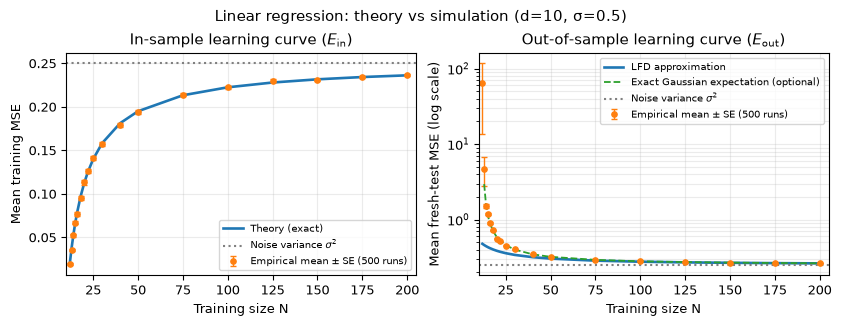

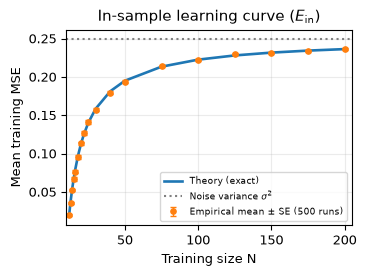

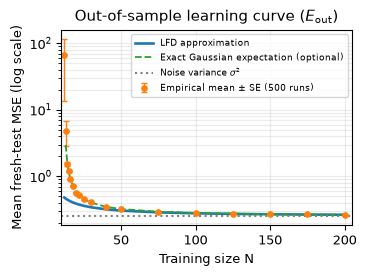

All figures saved to: D:\ROBT407\ROBT407_Part2_Complete\figures


In [17]:
plt.rcParams.update({'font.size':9, 'pdf.fonttype':42, 'ps.fonttype':42})

def plot_in_sample(ax):
    ax.plot(N_VALUES, ein_theory, '-', lw=1.9, label='Theory (exact)')
    ax.errorbar(N_VALUES, ein_mean, yerr=ein_se, fmt='o', markersize=3.8,
                capsize=2.0, lw=1, label=f'Empirical mean ± SE ({RUNS} runs)')
    ax.axhline(SIGMA**2, ls=':', color='gray', label=r'Noise variance $\sigma^2$')
    ax.set(xlabel='Training size N', ylabel='Mean training MSE',
           title=r'In-sample learning curve ($E_{\mathrm{in}}$)')
    ax.set_xlim(10, 205)
    ax.grid(alpha=0.25)

def plot_out_sample(ax, include_exact=False):
    ax.plot(N_VALUES, eout_theory, '-', lw=1.9,
            label='LFD approximation')
    ax.errorbar(N_VALUES, eout_mean, yerr=eout_se, fmt='o', markersize=3.8,
                capsize=2.0, lw=1, label=f'Empirical mean ± SE ({RUNS} runs)')
    if include_exact:
        okay = np.isfinite(eout_exact)
        ax.plot(N_VALUES[okay], eout_exact[okay], linestyle='dashed', lw=1.3,
                label='Exact Gaussian expectation (optional)')
    ax.axhline(SIGMA**2, ls=':', color='gray', label=r'Noise variance $\sigma^2$')
    ax.set(xlabel='Training size N', ylabel='Mean fresh-test MSE (log scale)',
           title=r'Out-of-sample learning curve ($E_{\mathrm{out}}$)')
    ax.set_yscale('log')
    ax.set_xlim(10, 205)
    ax.grid(alpha=0.25, which='both')

fig, axs = plt.subplots(1, 2, figsize=(8.3, 3.15), constrained_layout=True)
plot_in_sample(axs[0])
plot_out_sample(axs[1], include_exact=True)
axs[0].legend(loc='lower right', fontsize=7)
axs[1].legend(loc='upper right', fontsize=7)
fig.suptitle('Linear regression: theory vs simulation (d=10, σ=0.5)', fontsize=11)
for ext in ('pdf','png'):
    fig.savefig(FIGURES_DIR/f'part2_4_learning_curves.{ext}',
                dpi=230, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(3.55, 2.65), constrained_layout=True)
plot_in_sample(ax)
ax.legend(fontsize=6.7)
for ext in ('pdf','png'):
    fig.savefig(FIGURES_DIR/f'part2_4_ein.{ext}', dpi=230, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(3.55, 2.65), constrained_layout=True)
plot_out_sample(ax, include_exact=True)
ax.legend(fontsize=6.5)
for ext in ('pdf','png'):
    fig.savefig(FIGURES_DIR/f'part2_4_eout.{ext}', dpi=230, bbox_inches='tight')
plt.show()

print('All figures saved to:', FIGURES_DIR.resolve())

The training error is expected to match the exact formula. The approximate test error can be far too small when $N$ is close to 11, since the fitted weights become very sensitive to noise. When the sample size grows, both errors get closer to the noise variance $\sigma^2=0.25$.

In [18]:
print(f'At N=12: test MSE = {eout_mean[0]:.3f} ± {eout_se[0]:.3f}, approximation = {eout_theory[0]:.3f}')
print(f'At N=200: test MSE = {eout_mean[-1]:.3f} ± {eout_se[-1]:.3f}, approximation = {eout_theory[-1]:.3f}')
assert RUNS >= 500 or FAST
assert np.all(np.isfinite(ein_mean)) and np.all(np.isfinite(eout_mean))

At N=12: test MSE = 65.666 ± 52.104, approximation = 0.479
At N=200: test MSE = 0.265 ± 0.000, approximation = 0.264


## 2.5 California housing

We use California Housing to see how the regression model performs on real data. The test set contains 20% of the observations and is separated before preprocessing. Feature scaling uses only the training set. We also fit a separate line to the single feature most correlated with the training targets.

### Load data

In [19]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
X_all = np.asarray(housing.data, dtype=float)
y_all = np.asarray(housing.target, dtype=float)
feature_names = list(housing.feature_names)
assert X_all.shape == (20640, 8)
print('Dataset:', X_all.shape)
print('Features:', feature_names)

Dataset: (20640, 8)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


### Split and fit

In [20]:
N = len(y_all)
order = np.random.default_rng(SEED).permutation(N)
n_test = int(round(0.20 * N))
test_idx = order[:n_test]
train_idx = order[n_test:]
assert len(np.intersect1d(train_idx, test_idx)) == 0
X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_test_raw, y_test = X_all[test_idx], y_all[test_idx]
assert len(y_train) == 16512 and len(y_test) == 4128
print(f"Train: {len(y_train):,} ({len(y_train)/N:.0%})")
print(f"Test:  {len(y_test):,} ({len(y_test)/N:.0%})")

Train: 16,512 (80%)
Test:  4,128 (20%)


In [21]:
X_train_std, X_test_std, train_means, train_stds = standardize(
    X_train_raw, X_test_raw
)
assert np.allclose(X_train_std.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train_std.std(axis=0), 1, atol=1e-10)

X_train = add_bias(X_train_std)
X_test = add_bias(X_test_std)
w_hat = linear_lstsq(X_train, y_train)
assert np.all(np.isfinite(w_hat)) and w_hat.shape == (9,)
print("Parameters (bias + 8 standardized features):", w_hat.shape)
print("Training matrix condition number:", f"{np.linalg.cond(X_train):.3f}")

Parameters (bias + 8 standardized features): (9,)
Training matrix condition number: 6.402


### Test results

In [22]:
train_pred = X_train @ w_hat
test_pred = X_test @ w_hat
train_mse = mse(y_train, train_pred)
test_mse = mse(y_test, test_pred)
test_r2 = r2_score_numpy(y_test, test_pred)
test_residual = y_test - test_pred

assert np.all(np.isfinite(test_pred))
assert train_mse >= 0 and test_mse >= 0
print(f"Train MSE: {train_mse:.6f} ($100,000)^2")
print(f"TEST  MSE: {test_mse:.6f} ($100,000)^2")
print(f"TEST  R²:  {test_r2:.6f}")

Train MSE: 0.511782 ($100,000)^2
TEST  MSE: 0.590990 ($100,000)^2
TEST  R²:  0.566249


### Best single feature

In [23]:
y_c = y_train - y_train.mean()
X_c = X_train_raw - X_train_raw.mean(axis=0)
correlations = (X_c.T @ y_c) / np.sqrt(
    np.sum(X_c**2, axis=0) * np.sum(y_c**2)
)
assert np.all(np.isfinite(correlations))
best_idx = int(np.argmax(np.abs(correlations)))
best_feature = feature_names[best_idx]
best_correlation = float(correlations[best_idx])

# In raw units, a straight line is easy to interpret visually.
X_one = add_bias(X_train_raw[:, [best_idx]])
w_one = linear_lstsq(X_one, y_train)
print(f"Selected feature: {best_feature}")
print(f"Training Pearson r: {best_correlation:.5f}")
print(f"One-feature intercept: {w_one[0]:.6f}")
print(f"One-feature slope:     {w_one[1]:.6f} ($100,000 per feature unit)")

Selected feature: MedInc
Training Pearson r: 0.69057
One-feature intercept: 0.451902
One-feature slope:     0.417947 ($100,000 per feature unit)


### Coefficients

In [24]:
coef_order = np.argsort(-np.abs(w_hat[1:]))
print(f"Intercept: {w_hat[0]:+.5f} ($100,000)")
print("Standardized coefficients (sorted by magnitude):")
for j in coef_order:
    print(f"  {feature_names[j]:<12} {w_hat[j+1]:+.6f}")

# Purely training-data diagnostic: pairwise predictor correlations.
corr_mat = np.corrcoef(X_train_raw, rowvar=False)
upper = np.triu_indices(len(feature_names), 1)
order_pair = np.argsort(-np.abs(corr_mat[upper]))
print("Three strongest feature-pair correlations (training only):")
for k in order_pair[:3]:
    i, j = upper[0][k], upper[1][k]
    print(f"  {feature_names[i]} / {feature_names[j]}: r={corr_mat[i,j]:+.3f}")

Intercept: +2.07144 ($100,000)
Standardized coefficients (sorted by magnitude):
  Latitude     -0.898211
  Longitude    -0.872232
  MedInc       +0.852219
  AveBedrms    +0.315686
  AveRooms     -0.271999
  HouseAge     +0.118986
  AveOccup     -0.047248
  Population   -0.001127
Three strongest feature-pair correlations (training only):
  Latitude / Longitude: r=-0.925
  AveRooms / AveBedrms: r=+0.798
  MedInc / AveRooms: r=+0.376


The coefficients are based on standardized features, so each one corresponds to a change of one training standard deviation. When predictors are strongly correlated, their individual coefficients can be misleading even if the predictions are reasonable.

### Plots

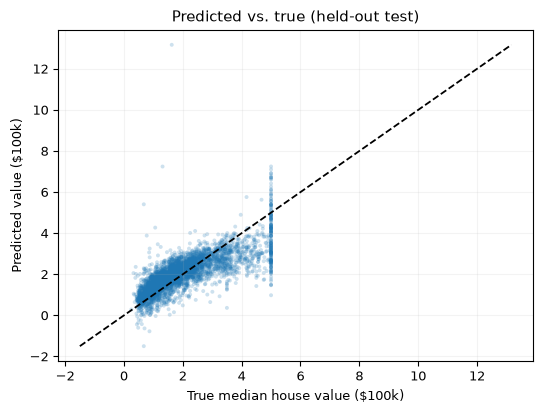

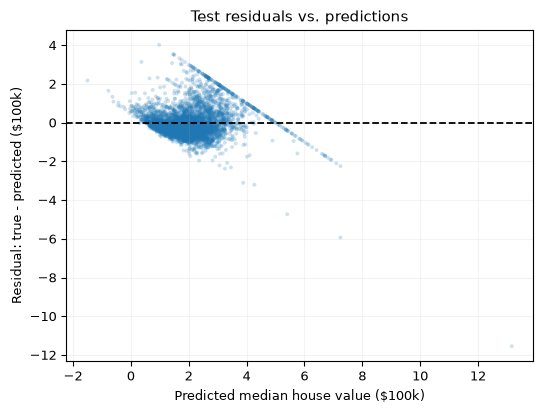

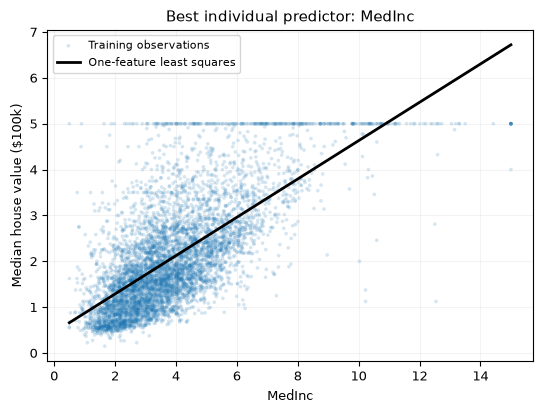

Saved three individual figures as PDF and PNG in D:\ROBT407\ROBT407_Part2_Complete\figures


In [25]:
# Use deterministic subsampling ONLY for visual display; all 16,512
# training observations are used to fit the one-feature line.
rng_viz = np.random.default_rng(SEED + 1000)
n_plot = min(1000 if FAST else 6000, len(y_train))
viz_ids = rng_viz.choice(len(y_train), size=n_plot, replace=False)

fig1, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(y_test, test_pred, s=8, alpha=0.22, edgecolors="none")
low = min(y_test.min(), test_pred.min())
high = max(y_test.max(), test_pred.max())
ax.plot([low, high], [low, high], linestyle='dashed', color="black", linewidth=1.3)
ax.set(xlabel="True median house value ($100k)",
       ylabel="Predicted value ($100k)",
       title="Predicted vs. true (held-out test)")
ax.grid(alpha=0.15)
fig1.tight_layout()
fig1.savefig(FIG_DIR / "part2_5_predicted_vs_true.pdf", bbox_inches="tight")
fig1.savefig(FIG_DIR / "part2_5_predicted_vs_true.png", dpi=180, bbox_inches="tight")
plt.show()

fig2, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(test_pred, test_residual, s=8, alpha=0.22, edgecolors="none")
ax.axhline(0, color="black", linestyle='dashed', linewidth=1.3)
ax.set(xlabel="Predicted median house value ($100k)",
       ylabel="Residual: true - predicted ($100k)",
       title="Test residuals vs. predictions")
ax.grid(alpha=0.15)
fig2.tight_layout()
fig2.savefig(FIG_DIR / "part2_5_residuals.pdf", bbox_inches="tight")
fig2.savefig(FIG_DIR / "part2_5_residuals.png", dpi=180, bbox_inches="tight")
plt.show()

fig3, ax = plt.subplots(figsize=(5.5, 4.2))
x1_all = X_train_raw[:, best_idx]
ax.scatter(x1_all[viz_ids], y_train[viz_ids], s=7, alpha=0.18,
           edgecolors="none", label="Training observations")
xline = np.linspace(x1_all.min(), x1_all.max(), 250)
yline = w_one[0] + w_one[1] * xline
ax.plot(xline, yline, color="black", linewidth=2, label="One-feature least squares")
ax.set(xlabel=best_feature, ylabel="Median house value ($100k)",
       title=f"Best individual predictor: {best_feature}")
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.15)
fig3.tight_layout()
fig3.savefig(FIG_DIR / "part2_5_best_feature.pdf", bbox_inches="tight")
fig3.savefig(FIG_DIR / "part2_5_best_feature.png", dpi=180, bbox_inches="tight")
plt.show()

print("Saved three individual figures as PDF and PNG in", FIG_DIR.resolve())

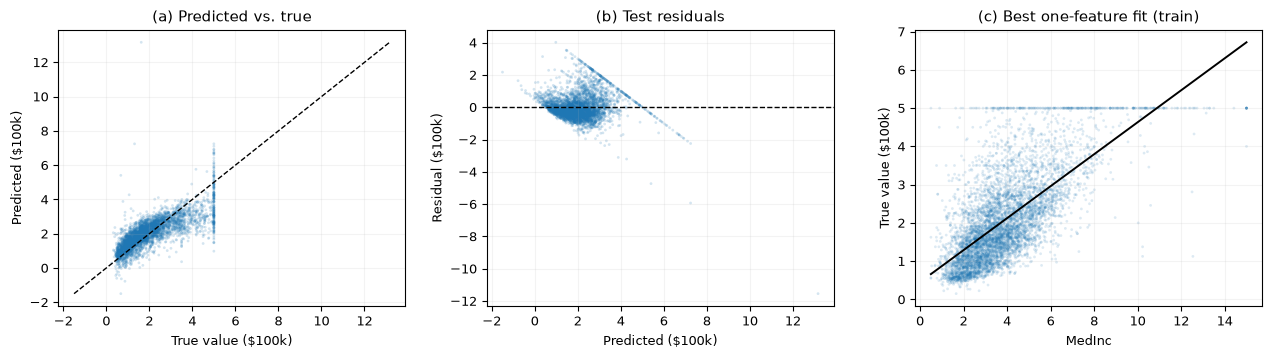

Saved combined Overleaf figure.


In [26]:
fig, axs = plt.subplots(1, 3, figsize=(12.8, 3.65))
ax = axs[0]
ax.scatter(y_test, test_pred, s=4, alpha=0.19, edgecolors="none")
ax.plot([low, high], [low, high], linestyle='dashed', color="black", lw=1.0)
ax.set(xlabel="True value ($100k)", ylabel="Predicted ($100k)", title="(a) Predicted vs. true")

ax = axs[1]
ax.scatter(test_pred, test_residual, s=4, alpha=0.19, edgecolors="none")
ax.axhline(0, color="black", ls='dashed', lw=1.0)
ax.set(xlabel="Predicted ($100k)", ylabel="Residual ($100k)", title="(b) Test residuals")

ax = axs[2]
ax.scatter(x1_all[viz_ids], y_train[viz_ids], s=4, alpha=0.15, edgecolors="none")
ax.plot(xline, yline, color="black", lw=1.4)
ax.set(xlabel=best_feature, ylabel="True value ($100k)", title="(c) Best one-feature fit (train)")

for ax in axs:
    ax.grid(alpha=0.15)
fig.tight_layout(w_pad=2.0)
fig.savefig(FIG_DIR / "part2_5_california_housing_combined.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "part2_5_california_housing_combined.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved combined Overleaf figure.")

### Save numbers

In [27]:
import matplotlib
import sklearn
import json

summary = {
    "dataset": "fetch_california_housing",
    "seed": SEED,
    "train_size": int(len(y_train)), "test_size": int(len(y_test)),
    "train_mse": float(train_mse),
    "test_mse": float(test_mse), "test_r2": float(test_r2),
    "selected_training_feature": best_feature,
    "selected_feature_training_pearson_r": best_correlation,
    "standardized_coefficients": {
        "bias": float(w_hat[0]),
        **{name: float(w_hat[i+1]) for i, name in enumerate(feature_names)}
    },
    "simple_regression_coefficients": {
        "intercept": float(w_one[0]), "slope": float(w_one[1])
    },
    "software": {
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "scikit_learn_data_loader": sklearn.__version__
    }
}
(RESULTS_DIR / "part2_5_summary.json").write_text(json.dumps(summary, indent=2))

895

The MSE and $R^2$ summarize prediction accuracy. The predicted versus true plot shows the overall agreement, and the residual plot helps show errors and patterns that the linear model cannot capture. The one-feature line illustrates the relation between the most predictive individual feature and house values.

## 2.6 Library comparison

We compare my NumPy least squares coefficients with scikit-learn and measure the running time of the five solvers. The methods use the same input data in each case. The data generation and warm-up are not included in the measured time.

With `FAST = False`, the experiment uses at least 20 timing repeats, with sample size up to $10^6$ and feature count up to 1000. The full runs can take considerably longer than the other sections.

### Compare coefficients

In [28]:
# Scikit-learn is used only in this labeled library comparison section.
from sklearn.linear_model import LinearRegression

reference_model = LinearRegression(fit_intercept=False)
reference_model.fit(X_train, y_train)
reference_w = reference_model.coef_
coefficient_gap = np.max(np.abs(w_hat - reference_w))
print(f'Maximum coefficient difference: {coefficient_gap:.3e}')
assert coefficient_gap < 1e-4

Maximum coefficient difference: 2.665e-15


### Timing setup

In [29]:
# All solvers receive a matrix that already includes the bias column.
# We fit without a separate intercept for the library implementation.

def solver_for_time(name, X, y):
    if name == 'Naive inverse':
        return solve_naive_inverse(X, y)
    if name == 'SVD':
        return solve_svd(X, y)
    if name == 'LSTSQ':
        return solve_lstsq(X, y)
    if name == 'Batch GD':
        return solve_gd(X, y, tol=1e-6, max_iter=500)[0]
    if name == 'L-BFGS-B':
        return solve_lbfgs(X, y, tol=1e-6, max_iter=500).x
    if name == 'sklearn':
        return LinearRegression(fit_intercept=False).fit(X, y).coef_
    raise ValueError(name)

SOLVER_NAMES = ['Naive inverse', 'SVD', 'LSTSQ', 'Batch GD', 'L-BFGS-B', 'sklearn']
TIMING_REPEATS = 3 if FAST else 20
N_GRID = np.array([1000, 10000, 100000] if FAST
                  else [1000, 3162, 10000, 31623, 100000, 316228, 1000000])
D_GRID = np.array([10, 30, 100] if FAST
                  else [10, 20, 50, 100, 200, 500, 1000])
print(f'Timing repeats: {TIMING_REPEATS}')
print('N grid:', N_GRID)
print('d grid:', D_GRID)

Timing repeats: 20
N grid: [   1000    3162   10000   31623  100000  316228 1000000]
d grid: [  10   20   50  100  200  500 1000]


### Time the solvers

In [30]:
def benchmark_one_case(N, d, seed, experiment):
    local_rng = np.random.default_rng(seed)
    X_bench = add_bias(local_rng.normal(size=(N, d)))
    w_bench = local_rng.normal(size=d + 1)
    y_bench = X_bench @ w_bench + 0.1 * local_rng.normal(size=N)
    rows = []
    for name in SOLVER_NAMES:
        durations = []
        fail_reason = ''
        try:
            # A warm-up call makes the timing less dependent on first-run costs.
            solver_for_time(name, X_bench, y_bench)
            for _ in range(TIMING_REPEATS):
                start = time.perf_counter()
                estimated = solver_for_time(name, X_bench, y_bench)
                duration = time.perf_counter() - start
                if not np.all(np.isfinite(estimated)):
                    raise FloatingPointError('Nonfinite coefficients')
                durations.append(duration)
                last_mse = linear_loss(estimated, X_bench, y_bench)
        except Exception as error:
            fail_reason = f'{type(error).__name__}: {error}'
        if durations and not fail_reason:
            median = float(np.median(durations))
            q25, q75 = np.percentile(durations, [25, 75])
        else:
            median, q25, q75 = np.nan, np.nan, np.nan
        rows.append({
            'N': int(N), 'd': int(d), 'experiment': experiment, 'solver': name,
            'median_seconds': median,
            'q25_seconds': float(q25), 'q75_seconds': float(q75),
            'successful_repeats': len(durations),
            'requested_repeats': TIMING_REPEATS,
            'last_mse': float(last_mse) if durations else np.nan,
            'failure': fail_reason
        })
    return rows

# Save after each size, so a long full run keeps completed results.
timing_rows = []
for i, n in enumerate(N_GRID):
    print(f'N benchmark {i+1}/{len(N_GRID)}: N={n}, d=20')
    timing_rows.extend(benchmark_one_case(int(n), 20, SEED + 100 + i, 'vary_N'))
    with (RESULTS_DIR / 'part2_6_timing_partial.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(timing_rows[0]))
        writer.writeheader()
        writer.writerows(timing_rows)
for i, d in enumerate(D_GRID):
    print(f'd benchmark {i+1}/{len(D_GRID)}: N=10000, d={d}')
    timing_rows.extend(benchmark_one_case(10000, int(d), SEED + 200 + i, 'vary_d'))
    with (RESULTS_DIR / 'part2_6_timing_partial.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(timing_rows[0]))
        writer.writeheader()
        writer.writerows(timing_rows)
print('Finished timing. Saved results/part2_6_timing_partial.csv')

N benchmark 1/7: N=1000, d=20
N benchmark 2/7: N=3162, d=20
N benchmark 3/7: N=10000, d=20
N benchmark 4/7: N=31623, d=20
N benchmark 5/7: N=100000, d=20
N benchmark 6/7: N=316228, d=20
N benchmark 7/7: N=1000000, d=20
d benchmark 1/7: N=10000, d=10
d benchmark 2/7: N=10000, d=20
d benchmark 3/7: N=10000, d=50
d benchmark 4/7: N=10000, d=100
d benchmark 5/7: N=10000, d=200
d benchmark 6/7: N=10000, d=500
d benchmark 7/7: N=10000, d=1000
Finished timing. Saved results/part2_6_timing_partial.csv


### Timing plots

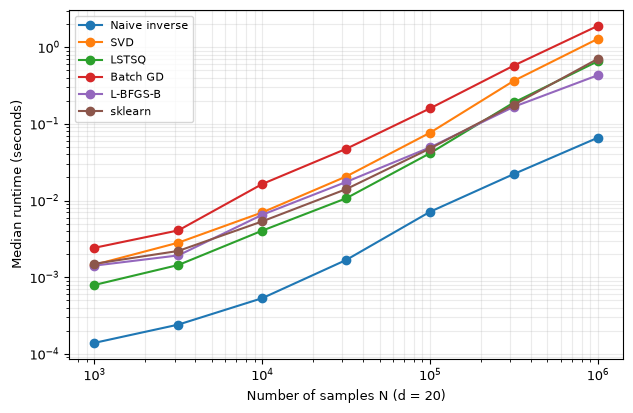

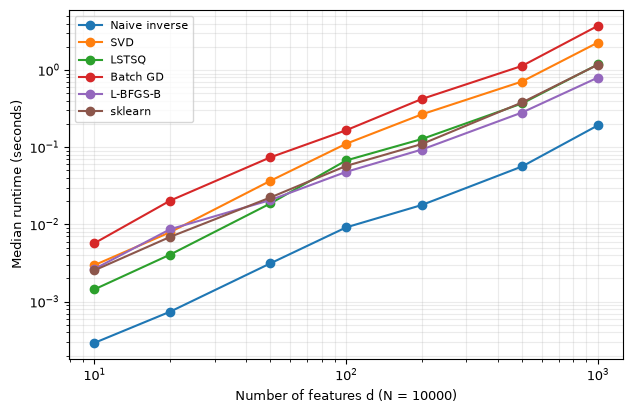

Failed cases: 0
Library coefficient difference: 2.665e-15
Log-log timing slopes: vary_N
  Naive inverse    0.93
  SVD              1.01
  LSTSQ            1.00
  Batch GD         1.00
  L-BFGS-B         0.87
  sklearn          0.91
Log-log timing slopes: vary_d
  Naive inverse    1.38
  SVD              1.43
  LSTSQ            1.43
  Batch GD         1.35
  L-BFGS-B         1.18
  sklearn          1.29


In [31]:
def plot_timing(x_key, experiment, filename, xlabel):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    for name in SOLVER_NAMES:
        selected = sorted(
            [row for row in timing_rows
             if row['solver'] == name and row['experiment'] == experiment
             and np.isfinite(row['median_seconds']) and row['median_seconds'] > 0],
            key=lambda row: row[x_key]
        )
        if selected:
            ax.loglog([row[x_key] for row in selected],
                      [row['median_seconds'] for row in selected], 'o-', label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Median runtime (seconds)')
    ax.grid(alpha=0.25, which='both')
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{filename}.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / f'{filename}.png', dpi=180, bbox_inches='tight')
    plt.show()

plot_timing('N', 'vary_N', 'part2_6_time_vs_N', 'Number of samples N (d = 20)')
plot_timing('d', 'vary_d', 'part2_6_time_vs_d', 'Number of features d (N = 10000)')

failed = [r for r in timing_rows if r['failure']]
print('Failed cases:', len(failed))
for row in failed:
    print(row['solver'], 'N =', row['N'], 'd =', row['d'], row['failure'])
print('Library coefficient difference:', f'{coefficient_gap:.3e}')

# Estimate the slope of each timing curve on the log scale.
# These slopes are empirical and can vary with the computer.
for experiment, x_key in [('vary_N', 'N'), ('vary_d', 'd')]:
    print('Log-log timing slopes:', experiment)
    for name in SOLVER_NAMES:
        selected = sorted(
            [r for r in timing_rows if r['experiment'] == experiment
             and r['solver'] == name and np.isfinite(r['median_seconds'])
             and r['median_seconds'] > 0], key=lambda r: r[x_key])
        if len(selected) >= 3:
            xs = np.log([r[x_key] for r in selected])
            ys = np.log([r['median_seconds'] for r in selected])
            slope = np.polyfit(xs, ys, 1)[0]
            print(f'  {name:<16} {slope:.2f}')


As the number of samples grows, each method must work with a larger matrix. As the number of features grows, matrix factorizations usually become more expensive. The inverse is especially costly and can be unstable. The timing plots will show how these differences appear in practice. We use median runtime because individual measurements can vary with background processes.

## 2.7 Digits classification

Finally, we use linear regression to classify handwritten digits 1 and 5. We use the same two features specified in Part 1: intensity and left-right symmetry. The test split is stratified, and the features are scaled using training values only. We compare the sign of the regression output with Pocket PLA, including Pocket initialized with the regression weights.

### Data and features

In [32]:
from sklearn.datasets import load_digits

digits = load_digits()
selected = np.isin(digits.target, [1, 5])
images = digits.images[selected].astype(float)
labels = np.where(digits.target[selected] == 1, 1, -1)
intensity = images.mean(axis=(1, 2))
symmetry = -np.abs(images - images[:, :, ::-1]).mean(axis=(1, 2))
raw_features = np.column_stack([intensity, symmetry])

train_ids, test_ids = stratified_split(labels, 0.30, np.random.default_rng(SEED))
f_train, f_test = raw_features[train_ids], raw_features[test_ids]
y_digits_train, y_digits_test = labels[train_ids], labels[test_ids]

# Scale each feature to [-1, 1] based on training data only.
f_min = f_train.min(axis=0)
f_max = f_train.max(axis=0)
f_range = np.where(f_max > f_min, f_max - f_min, 1.0)
scaled_train = 2 * (f_train - f_min) / f_range - 1
scaled_test = 2 * (f_test - f_min) / f_range - 1
X_digits_train = add_bias(scaled_train)
X_digits_test = add_bias(scaled_test)
print('Train:', X_digits_train.shape, '| Test:', X_digits_test.shape)
print('Labels: +1 for digit 1, -1 for digit 5')

Train: (254, 3) | Test: (110, 3)
Labels: +1 for digit 1, -1 for digit 5


### Train models

In [33]:
def classification_error(X, y, w):
    return np.mean(np.sign(X @ w) != y)

w_lin_digits = solve_lstsq(X_digits_train, y_digits_train)
pocket_zero, history_zero = pocket_pla(
    X_digits_train, y_digits_train, 1000,
    np.random.default_rng(SEED), w0=np.zeros(X_digits_train.shape[1])
)
pocket_linear, history_linear = pocket_pla(
    X_digits_train, y_digits_train, 1000,
    np.random.default_rng(SEED), w0=w_lin_digits
)
models = {
    'Linear regression': w_lin_digits,
    'Pocket from zero': pocket_zero,
    'Pocket from linear': pocket_linear
}
print(f"{'Model':<22} {'Ein':>10} {'Etest':>10}")
for name, w in models.items():
    print(f'{name:<22} {classification_error(X_digits_train, y_digits_train, w):>10.4f} '
          f'{classification_error(X_digits_test, y_digits_test, w):>10.4f}')

print('Initial linear regression error:', classification_error(X_digits_train, y_digits_train, w_lin_digits))

Model                         Ein      Etest
Linear regression          0.4488     0.4000
Pocket from zero           0.3661     0.3727
Pocket from linear         0.3701     0.2909
Initial linear regression error: 0.44881889763779526


### Decision boundaries

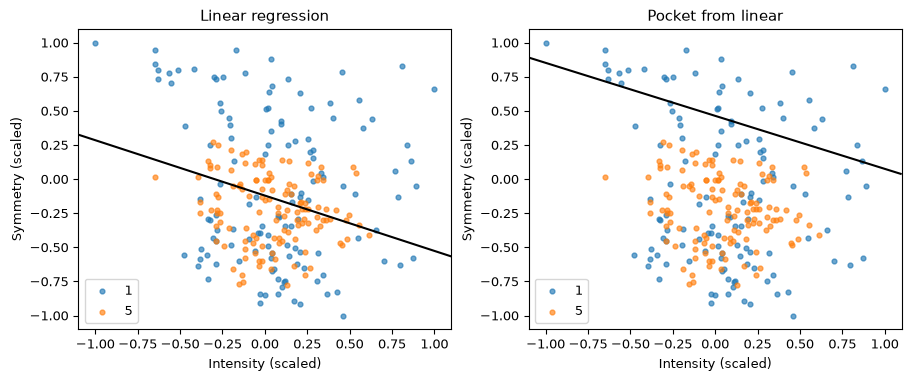

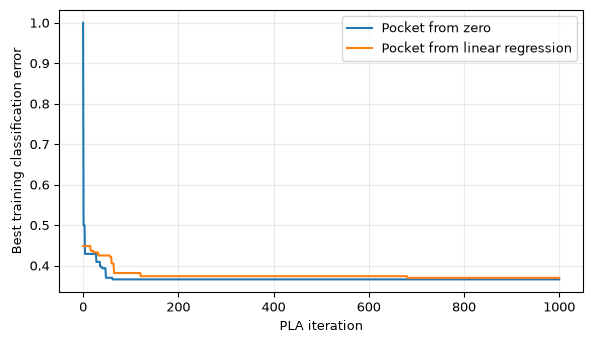

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.7), constrained_layout=True)
xx = np.linspace(scaled_train[:, 0].min() - 0.1, scaled_train[:, 0].max() + 0.1, 150)
yy = np.linspace(scaled_train[:, 1].min() - 0.1, scaled_train[:, 1].max() + 0.1, 150)
mx, my = np.meshgrid(xx, yy)
zz = add_bias(np.column_stack([mx.ravel(), my.ravel()]))
for ax, (title, w) in zip(axs, [('Linear regression', w_lin_digits),
                                ('Pocket from linear', pocket_linear)]):
    ax.scatter(scaled_train[y_digits_train == 1, 0],
               scaled_train[y_digits_train == 1, 1], s=12, alpha=0.65, label='1')
    ax.scatter(scaled_train[y_digits_train == -1, 0],
               scaled_train[y_digits_train == -1, 1], s=12, alpha=0.65, label='5')
    ax.contour(mx, my, (zz @ w).reshape(mx.shape), levels=[0], colors='black')
    ax.set_title(title)
    ax.set_xlabel('Intensity (scaled)')
    ax.set_ylabel('Symmetry (scaled)')
    ax.legend()
fig.savefig(FIG_DIR / 'part2_7_digit_boundaries.pdf', bbox_inches='tight')
fig.savefig(FIG_DIR / 'part2_7_digit_boundaries.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history_zero, label='Pocket from zero')
ax.plot(history_linear, label='Pocket from linear regression')
ax.set(xlabel='PLA iteration', ylabel='Best training classification error')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'part2_7_pocket_history.pdf', bbox_inches='tight')
plt.show()

Linear regression was trained to minimize squared error, not the number of wrong labels. Pocket directly keeps the weights with the lowest training classification error seen during its updates. Starting Pocket with $w_{\mathrm{lin}}$ may give it a better starting boundary than starting from zero. Whether it also improves test error depends on the data.